# Visualizing Proteins with NGL Viewer in Jupyter

An interactive tour of **[NGL Viewer](https://www.rcsb.org/nglviewer)**, the WebGL structure
viewer behind the RCSB PDB website, driven entirely from Python inside a Jupyter notebook.

The running example is **hemoglobin** — a textbook molecule with a biological story that
structure visualization makes obvious: an $\alpha_2\beta_2$ tetramer, an all-alpha fold,
buried heme prosthetic groups, and a measurable structural difference between the
oxygenated and deoxygenated states.

### What this notebook covers

| Section | Topic |
| --- | --- |
| 1 | Loading a structure and summarising it with Biopython |
| 2 | Cartoon, surface, ball+stick and licorice representations |
| 3 | The NGL selection language |
| 4 | Built-in colour schemes (`sstruc`, `hydrophobicity`, `bfactor`, …) |
| 5 | Fading and restyling representations |
| 6 | Computing a binding pocket in Python, rendering it in NGL |
| 7 | Side-by-side structures and the oxy/deoxy Fe displacement |
| 8 | Custom colour schemes |
| 9 | AlphaFold pLDDT and PAE |
| 10 | Exporting images and standalone HTML |

### Structures used

| PDB ID | Description | Resolution |
| --- | --- | --- |
| `1HHO` | Human **oxy**haemoglobin | 2.10 Å |
| `2HHB` | Human **deoxy**haemoglobin | 1.74 Å |
| `AF-P69905-F1` | AlphaFold model of human haemoglobin subunit alpha | — |

### Requirements

```bash
pip install nglview biopython numpy matplotlib ipywidgets
```

> Targets **nglview 4.x**. The API differs from 3.x in several places that bite silently, and
> the differences are called out where they matter below.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import nglview as nv
import numpy as np
import requests
from Bio import __version__ as biopython_version
from Bio.Data.IUPACData import protein_letters_3to1
from Bio.PDB import MMCIFParser
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from IPython.display import display
from ipywidgets import GridBox, HBox, Layout, ToggleButtons, VBox
from nglview.color import ColormakerRegistry

print(f"nglview {nv.__version__}")
print(f"biopython {biopython_version}; numpy {np.__version__}")

nglview 4.0.1
biopython 1.88; numpy 2.5.3


---
## 1. Fetching structures and summarising them

NGL can load a structure straight from RCSB by PDB ID:

```python
view = nglview.show_pdbid("1HHO")
```

That is fine for interactive poking around, but it gives no handle on the data and no
caching. It is usually better to download the mmCIF once, cache it on disk, and then point
both Biopython and NGL at the same file — so the analysis and the rendering are guaranteed
to describe identical coordinates.

In [2]:
CACHE = Path(".structure_cache")
CACHE.mkdir(exist_ok=True)

RCSB_FILE = "https://files.rcsb.org/download/{pdb_id}.cif"
RCSB_ENTRY = "https://data.rcsb.org/rest/v1/core/entry/{pdb_id}"
ALPHAFOLD_API = "https://alphafold.ebi.ac.uk/api/prediction/{uniprot}"
ALPHAFOLD_FILE = "https://alphafold.ebi.ac.uk/files/{model}-model_v{version}.cif"
ALPHAFOLD_PAE = "https://alphafold.ebi.ac.uk/files/{model}-predicted_aligned_error_v{version}.json"


def fetch(url, force=False):
    """GET `url`, cache the bytes under `.structure_cache/`, return the Path.

    Caching makes a second run instant, works offline, and pins repeat
    experiments to byte-identical coordinates.
    """
    target = CACHE / url.rsplit("/", 1)[-1].split("?")[0].lower()
    if target.exists() and not force:
        return target
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    target.write_bytes(response.content)
    return target


def entry_metadata(pdb_id):
    return requests.get(RCSB_ENTRY.format(pdb_id=pdb_id), timeout=60).json()

In [3]:
OXY_PDB_ID = "1HHO"    # human oxyhaemoglobin,   2.10 A
DEOXY_PDB_ID = "2HHB"  # human deoxyhaemoglobin, 1.74 A

oxy_cif = fetch(RCSB_FILE.format(pdb_id=OXY_PDB_ID))
deoxy_cif = fetch(RCSB_FILE.format(pdb_id=DEOXY_PDB_ID))

for pdb_id, path in ((OXY_PDB_ID, oxy_cif), (DEOXY_PDB_ID, deoxy_cif)):
    meta = entry_metadata(pdb_id)
    resolution = meta["rcsb_entry_info"]["resolution_combined"][0]
    print(f"{pdb_id}  {resolution:.2f} A  {meta['exptl'][0]['method']}")
    print(f"        {meta['struct']['title']}")
    print(f"        {path.name}  ({path.stat().st_size / 1024:.0f} KiB cached)")

1HHO  2.10 A  X-RAY DIFFRACTION
        STRUCTURE OF HUMAN OXYHAEMOGLOBIN AT 2.1 ANGSTROMS RESOLUTION
        1hho.cif  (297 KiB cached)


2HHB  1.74 A  X-RAY DIFFRACTION
        THE CRYSTAL STRUCTURE OF HUMAN DEOXYHAEMOGLOBIN AT 1.74 ANGSTROMS RESOLUTION
        2hhb.cif  (522 KiB cached)


In [4]:
# `protein_letters_3to1` is keyed by capitalised three-letter codes ('Ala'), while
# residues report upper-case names ('ALA'), so the lookup needs `capitalize()`.
THREE_TO_ONE = {k.capitalize(): v for k, v in protein_letters_3to1.items()}


def summarise(path, structure_id):
    """Parse a structure file; return (structure, model, per-chain summaries)."""
    structure = MMCIFParser(QUIET=True).get_structure(structure_id, str(path))
    model = next(structure.get_models())

    chains = []
    for chain in model:
        residues = [r for r in chain if r.id[0] == " "]  # standard amino acids
        if not residues:
            continue
        ligands = {}
        for residue in chain:
            if residue.id[0] != " ":
                ligands[residue.get_resname()] = ligands.get(residue.get_resname(), 0) + 1
        chains.append(
            {
                "chain": chain.id,
                "n_residues": len(residues),
                "sequence": "".join(
                    THREE_TO_ONE.get(r.get_resname().capitalize(), "X") for r in residues
                ),
                "hetero": ligands,
            }
        )
    return structure, model, chains


oxy_structure, oxy_model, oxy_chains = summarise(oxy_cif, OXY_PDB_ID)
deoxy_structure, deoxy_model, deoxy_chains = summarise(deoxy_cif, DEOXY_PDB_ID)

for pdb_id, chains in ((OXY_PDB_ID, oxy_chains), (DEOXY_PDB_ID, deoxy_chains)):
    print(f"\n{pdb_id}")
    for info in chains:
        extra = ", ".join(f"{n}x {k}" for k, n in sorted(info["hetero"].items())) or "none"
        print(f"  chain {info['chain']}: {info['n_residues']:>3} residues | hetero: {extra}")
    print(f"    first 20 residues of chain {chains[0]['chain']}: {chains[0]['sequence'][:20]}")


1HHO
  chain A: 141 residues | hetero: 1x HEM, 48x HOH, 1x OXY, 1x PO4
  chain B: 146 residues | hetero: 1x HEM, 61x HOH, 1x OXY
    first 20 residues of chain A: VLSPADKTNVKAAWGKVGAH

2HHB
  chain A: 141 residues | hetero: 1x HEM, 58x HOH
  chain B: 146 residues | hetero: 1x HEM, 58x HOH, 1x PO4
  chain C: 141 residues | hetero: 1x HEM, 58x HOH
  chain D: 146 residues | hetero: 1x HEM, 47x HOH, 1x PO4
    first 20 residues of chain A: VLSPADKTNVKAAWGKVGAH


Reading the output:

* `1HHO` is the classic **$\alpha\beta$ dimer**. Chain A is the 141-residue alpha subunit
  (`VLSPADKTNVKAAWGKVGAH` — the N-terminal Val-Leu dipeptide, a historical marker of adult
  haemoglobin), chain B is the 146-residue beta subunit. `HEM` are the heme prosthetic
  groups and `OXY` is the bound dioxygen.
* `2HHB` is the full **$\alpha_2\beta_2$ tetramer** (chains A/B plus C/D) and — this is the
  entire reason for using it — it has **no `OXY` residue**, because it is deoxygenated.

> `2HHB` has the *better* resolution (1.74 Å vs 2.10 Å) but the *larger* assembly. Both are
> good structures; just do not compare their B-factors as though they came from one experiment.

### Secondary structure from the mmCIF records

Biopython can assign secondary structure with DSSP, but that needs an external `mkdssp`
binary and `Bio.PDB.SSSP` is not part of a default install. The author-supplied HELIX/SHEET
records are already in the mmCIF file, so read those. They are depositor-assigned rather than
DSSP-derived, which is adequate for a survey — and if you need real DSSP, run `mkdssp` and
parse its `.dssp` output.

In [5]:
def author_secondary_structure(path):
    """Residues covered by author HELIX records, and the number of SHEET ranges.

    The values live in the `_struct_conf` category, so `MMCIF2Dict` exposes them
    under the flattened keys `_struct_conf.conf_type_id`,
    `_struct_conf.beg_auth_seq_id` and so on. There is no bare `_struct_conf`
    key, and no `_struct_conf_num_bonds`; asking for either silently returns [].
    """
    record = MMCIF2Dict(str(path))
    conf_types = record.get("_struct_conf.conf_type_id", [])
    helix_residues = 0
    for beg, end in zip(
        record.get("_struct_conf.beg_auth_seq_id", []),
        record.get("_struct_conf.end_auth_seq_id", []),
        strict=False,
    ):
        try:
            helix_residues += int(end) - int(beg) + 1
        except ValueError:
            continue
    return {
        "helix_records": sum(1 for t in conf_types if str(t).startswith("HELX")),
        "helix_residues": helix_residues,
        "sheet_ranges": len(record.get("_struct_sheet_range.beg_auth_seq_id", [])),
    }


for pdb_id, path in ((OXY_PDB_ID, oxy_cif), (DEOXY_PDB_ID, deoxy_cif)):
    print(pdb_id, author_secondary_structure(path))

1HHO {'helix_records': 16, 'helix_residues': 224, 'sheet_ranges': 0}


2HHB {'helix_records': 32, 'helix_residues': 448, 'sheet_ranges': 0}


`1HHO` is essentially all helix — 224 residues across 16 helix records, no sheets.
`2HHB` doubles both, since it has twice the chains. That is expected for a globin fold, but
it is worth confirming rather than assuming: a structure with zero `HELX` records is a red
flag that you are reading the wrong keys, or parsing the wrong file. Both happened here
first — an earlier version asked for `_struct_conf` and `_struct_conf_num_bonds`, neither of
which exists, and reported a confident `0` for every structure.

---
## 2. Representations: from cartoon to surface

An NGL *representation* is a drawing style applied to a *selection*. That pair is the whole
mental model: `add_representation("cartoon", "protein")` means "draw a cartoon of everything
that is protein".

| `repr_type` | Good for |
| --- | --- |
| `cartoon` | Overall fold and secondary structure |
| `surface` | Molecular envelope, solvent-accessible shape |
| `ball+stick` | Ligands and cofactors — the default for "show me this molecule" |
| `licorice` | Bonds plus wide atoms; good for rings and side chains |
| `ribbon` | Thinner cartoon variant, better for long chains |
| `tube` | Main-chain trace; good for very large or low-resolution structures |
| `hyperball` | Chunky ball+stick |
| `contact` | Non-covalent contact surfaces between chains |
| `spacefill` | Space-filling, for showing molecular volume |

`add_representation` also forwards keyword arguments to the NGL JavaScript, camelising
Python `snake_case` automatically — `color_scheme`, `surface_type`, `use_worker`, `opacity`,
`aspect_ratio` and `depth_test` all work.

> **`shape` vs `layout`.** `view.shape = (520, 520)` sets the widget size. `view.layout` is
> an `ipywidgets.Layout` *object*, so `view.layout = "left"` raises a `TraitError`. Assign a
> `Layout(...)` if you need to, or just use `shape`.

In [6]:
view = nv.show_structure_file(str(oxy_cif), default_representation=False)
view.shape = (520, 520)
view

NGLWidget()

In [7]:
view.add_representation("cartoon", "protein", color_scheme="chainname", aspect_ratio=2.0)
view.add_representation("ball+stick", "hetero and not water", color_scheme="element")
view.center()

Now compare with a molecular surface. Surfaces are expensive, so NGL can compute them on a
web worker (`use_worker=True`) to keep the UI responsive.

In [8]:
surface_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
surface_view.shape = (520, 520)
surface_view.add_representation(
    "surface",
    "protein",
    color_scheme="sstruc",
    opacity=0.7,
    surface_type="molecular",
    use_worker=True,
)
surface_view.add_representation("ball+stick", "hetero and not water", color_scheme="element")
surface_view.center()
surface_view

NGLWidget()

In [9]:
# The same component drawn eight different ways. ipywidgets GridBox rather than
# nglview.sandbox.grid_view, which is written against the removed `.player` API.
STYLE_GRID = [
    ("cartoon", "protein", {}),
    ("tube", "protein", {"radius": 0.3}),
    ("ribbon", "protein", {}),
    ("surface", "protein", {"opacity": 0.5, "surface_type": "av", "use_worker": True}),
    ("ball+stick", "hetero and not water", {}),
    ("licorice", "hetero and not water", {}),
    ("spacefill", "hetero and not water", {"scale": 0.6}),
    ("contact", "protein", {"use_worker": True}),
]

style_panels = []
for repr_type, selection, kwargs in STYLE_GRID:
    panel = nv.NGLWidget()
    panel.shape = (260, 260)
    panel.add_component(str(oxy_cif), ext="cif", default_representation=False)
    panel.add_representation(repr_type, selection, **kwargs)
    panel.center()
    panel.layout = Layout(border="1px solid #cccccc")
    style_panels.append(panel)

display(
    GridBox(
        style_panels,
        layout={"grid_template_columns": "repeat(4, 260px)", "grid_gap": "8px"},
    )
)

GridBox(children=(NGLWidget(layout=Layout(border_bottom='1px solid #cccccc', border_left='1px solid #cccccc', …

Eight panels, one structure, eight styles — all through the same `add_representation`
signature. Change the `repr_type` string and the picture changes, which is the cheapest way
to learn what each style is actually showing.

---
## 3. The selection language

NGL uses a compact boolean selection language, the same family of syntax as PyMOL's
`select`. This is the single most useful thing to learn, because everything else in NGL is a
drawing style attached to a selection.

### Level 1 — keywords

```
all          everything
protein      standard amino acid residues
nucleic      DNA and RNA residues
hetero       any non-standard (heterogeneous) residue
ligand       a bound small molecule, excluding water and ions
ion          monoatomic ions
water        HOH and friends
polymer      protein or nucleic
hydrogen     hydrogen atoms
```

### Level 2 — secondary structure and chemistry

```
helix        residues in an alpha helix
sheet        residues in a beta strand
turn         residues in a turn
sidechain    non-backbone atoms
backbone     N, CA, C, O
hydrophobic  hydrophobic residues
aromatic     Phe, Tyr, Trp, His
charged      Lys, Arg, Asp, Glu
polar        Ser, Thr, Asn, Gln, ...
```

### Level 3 — properties and identifiers

```
42           residue number 42
3-40         residues 3 through 40 inclusive (no spaces)
5,7,9        a list
:A           chain A
:.,:D        chains A, B, C and D
.CA          atom name
ALA          residue name
@1,2,3       atom index
/0           model 0
```

Combine with `and`, `or`, `not`, and group with parentheses:

```python
"protein and :A and not helix and not 1-38"
```

> **Two traps.** `sstruc` and `hydrophobicity` are *colour schemes*, not selection keywords.
> And `secondary-structure c` is Mol\* syntax — in NGL use `helix` or `sheet`. When in doubt,
> click atoms in the 3D view: NGL's picker shows you the selection string for whatever you
> clicked, which is the authoritative check.

In [10]:
# The subset this notebook's sketch parser handles...
SELECTION_EXAMPLES = [
    ("the whole structure", "all"),
    ("protein only", "protein"),
    ("one chain", "protein and :A"),
    ("a residue range", "protein and 30-45"),
    ("aromatic side chains", "protein and aromatic"),
    ("charged residues", "protein and charged"),
    ("polar residues", "protein and polar"),
]

# ...and the rest, which NGL understands and the sketch does not.
BEYOND_THE_SKETCH = [
    ("the cofactors", "hetero and not water"),
    ("alpha helices only", "protein and helix"),
    ("beta strands only", "protein and sheet"),
    ("a pocket wall", "protein and hydrophobic and not :A"),
    ("excluded termini", "protein and not 1-38 and not 137-141"),
    ("one atom name", "protein and .CA"),
]

for label, selection in SELECTION_EXAMPLES + BEYOND_THE_SKETCH:
    print(f"{label:<24} {selection}")

the whole structure      all
protein only             protein
one chain                protein and :A
a residue range          protein and 30-45
aromatic side chains     protein and aromatic
charged residues         protein and charged
polar residues           protein and polar
the cofactors            hetero and not water
alpha helices only       protein and helix
beta strands only        protein and sheet
a pocket wall            protein and hydrophobic and not :A
excluded termini         protein and not 1-38 and not 137-141
one atom name            protein and .CA


### Previewing a selection before committing to it

A selection is just a string, so it is worth knowing how much it matches before rendering.
NGL and Biopython do not share a parser, so the honest approach is to write the predicate
explicitly in Biopython — which is also clearer than pretending a keyword table exists:

```python
selection = "protein and :A and 30-45"
```

becomes

```python
[residue for residue in model["A"]
 if residue.id[0] == " " and 30 <= residue.id[1] <= 45]
```

The helper below wraps that translation so the first list can be counted. It is a deliberate
sketch: `not` and `or` are not implemented, `helix`/`sheet` would need the HELIX/SHEET records
read back in, and a `.CA` atom-name filter is not a residue predicate at all. Crucially it
**raises** on anything it does not understand rather than quietly returning a subset — so the
six lines in the second group are the parser declining, not a silent under-count. Use it to
sanity-check, then confirm in the picker. For real work use `NeighborSearch` and
`Bio.PDB.Selection.unfold_neighbors` directly.

In [11]:
RESIDUE_KEYWORDS = {
    "protein": lambda r: r.id[0] == " ",
    "hetero": lambda r: r.id[0] != " ",
    "water": lambda r: r.get_resname() == "HOH",
    "aromatic": lambda r: r.get_resname() in {"PHE", "TYR", "TRP", "HIS"},
    "charged": lambda r: r.get_resname() in {"LYS", "ARG", "ASP", "GLU"},
    "hydrophobic": lambda r: r.get_resname() in {
        "ALA", "VAL", "LEU", "ILE", "MET", "PHE", "TRP", "PRO", "GLY", "CYS",
    },
    "polar": lambda r: r.get_resname() in {"SER", "THR", "ASN", "GLN", "TYR", "CYS"},
}


def match(model, selection):
    """Best-effort translation of a simple NGL selection into a residue list.

    Supports a chain filter, a residue number / range filter, and residue-name
    keywords joined by `and`. Raises ValueError on anything else.
    """
    chain_id = None
    numbers = None
    keywords = []

    for token in selection.replace("(", " ").replace(")", " ").split():
        if token in {"and", "all"}:
            continue
        if token in {"or", "not"}:
            raise ValueError(f"{token!r} is not implemented")
        if token.startswith(":") and len(token) > 1:
            chain_id = token[1:]
            continue
        if token.replace("-", "").isdigit():
            bounds = [int(x) for x in token.split("-")]
            numbers = range(min(bounds), max(bounds) + 1)
            continue
        if token in RESIDUE_KEYWORDS:
            keywords.append(token)
            continue
        raise ValueError(f"unsupported token {token!r} (atom-level selectors are not residues)")

    chains = [model[chain_id]] if chain_id else list(model)
    hits = []
    for chain in chains:
        for residue in chain:
            if numbers is not None and residue.id[1] not in numbers:
                continue
            if keywords and not all(RESIDUE_KEYWORDS[k](residue) for k in keywords):
                continue
            hits.append(residue)
    return hits


def preview(model, examples):
    """Print a count per selection, or the reason the sketch declined it."""
    for _label, selection in examples:
        try:
            hits = match(model, selection)
        except ValueError as exc:
            print(f"{selection:<42} declined: {exc}")
            continue
        atoms = sum(len(list(r)) for r in hits)
        print(f"{selection:<42} {len(hits):>4} residues {atoms:>5} atoms")


print("handled:")
preview(oxy_model, SELECTION_EXAMPLES)
print("\nnot handled (still valid NGL selections):")
preview(oxy_model, BEYOND_THE_SKETCH)

handled:
all                                         401 residues  2396 atoms
protein                                     287 residues  2192 atoms
protein and :A                              141 residues  1069 atoms
protein and 30-45                            32 residues   290 atoms
protein and aromatic                         43 residues   470 atoms
protein and charged                          55 residues   493 atoms
protein and polar                            55 residues   414 atoms

not handled (still valid NGL selections):
hetero and not water                       declined: 'not' is not implemented
protein and helix                          declined: unsupported token 'helix' (atom-level selectors are not residues)
protein and sheet                          declined: unsupported token 'sheet' (atom-level selectors are not residues)
protein and hydrophobic and not :A         declined: 'not' is not implemented
protein and not 1-38 and not 137-141       declined: 'not' is not imple

---
## 4. Colour schemes

`view.color_by(scheme, component=0)` recolours an existing representation. The same strings
work in `add_representation(color_scheme=...)`.

| Scheme | Colours by | Notable use |
| --- | --- | --- |
| `chainname` | Chain identifier | The default overview |
| `sstruc` | Secondary structure | Helix / sheet / coil colouring |
| `residueindex` | Residue number | Rainbow N to C |
| `hydrophobicity` | Kyte-Doolittle scale | Surface pockets and cores |
| `bfactor` | B-factor / pLDDT | Temperature factors, **and AlphaFold confidence** |
| `resname` | Residue type | |
| `element` | Chemical element | Ligands, cofactors |
| `volume` | Per-atom volume | Soft spheres |
| `occupancy` | Occupancy | Alternate conformations |
| `moleculetype` | Protein / DNA / RNA / ligand | Mixed selections |
| `uniform` | One flat colour | Where the colour is the point, not the information |

In [12]:
SCHEMES = ["sstruc", "chainname", "residueindex", "hydrophobicity", "moleculetype"]

color_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
color_view.shape = (520, 520)
color_view.add_representation("cartoon", "protein", color_scheme="sstruc")
color_view.center()

scheme_picker = ToggleButtons(options=SCHEMES, value="sstruc", description="colour by:")
scheme_picker.observe(lambda change: color_view.color_by(change["new"], 0), names="value")

VBox([color_view, scheme_picker])

`NGLWidget` is an ordinary ipywidgets widget, so `ToggleButtons.observe` drives it directly.
Note that `color_by` only sends a message to the JavaScript front end — if clicks do nothing,
check that widgets are enabled in the notebook rather than that the call is wrong.

In [13]:
# The same idea on a surface: hydrophobicity makes buried pockets obvious.
hp_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
hp_view.shape = (520, 520)
hp_view.add_representation(
    "surface", "protein", color_scheme="hydrophobicity", opacity=0.75, use_worker=True
)
hp_view.add_representation("ball+stick", "hetero and not water", color_scheme="element")
hp_view.center()
hp_view

NGLWidget()

Brown/orange is hydrophobic, blue is hydrophilic. The heme sits in an unmistakably
hydrophobic pocket, which is the right environment for binding nonpolar O<sub>2</sub>.

---
## 5. Fading and restyling an existing representation

Once a structure is loaded, the fastest way to answer a specific question is usually to
change what is already drawn rather than add more.

| Method | Effect |
| --- | --- |
| `view.update_representation(component, repr_index, **params)` | Change parameters of one representation |
| `view.set_representations(list_of_dicts, component=0)` | Replace all representations on a component |
| `view.clear_representations(component=0)` | Remove all representations on a component |
| `view.remove_component(view[0])` | Remove a whole component |
| `view.show_only(indices)` / `view.hide(indices)` | Show or hide **components**, by index |
| `view.color_by(scheme, component=0)` | Recolour representation 0 of a component |

> **Two API traps.** `show_only` and `hide` take **component indices**, not selection
> strings — `view.hide("protein and not helix")` fails with a `TypeError`. To dim a *region*
> of one structure, use `update_representation(opacity=...)` on a representation that covers
> that region, as below. Second, `remove_component` takes a UUID or a `ComponentViewer`
> (`view[0]`), not an integer index.

In [14]:
# A faint full-structure cartoon with the heme picked out on top.
pocket_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
pocket_view.shape = (520, 520)
pocket_view.add_representation("cartoon", "protein", color_scheme="chainname", opacity=0.25)
pocket_view.add_representation("ball+stick", "hetero and not water", color_scheme="element")
pocket_view.center()
pocket_view

NGLWidget()

`update_representation` addresses a representation by `(component, repr_index)` and takes the
same camelised parameters as `add_representation`. Drop the faint cartoon to a whisper, or
bring it back:

In [15]:
pocket_view.update_representation(0, repr_index=0, opacity=0.08)
pocket_view.update_representation(0, repr_index=1, color_scheme="sstruc")
pocket_view

NGLWidget()

`set_representations` replaces everything on a component in one call. Note the nested shape:
each entry has a `"type"` and a `"params"` dict, and the selection key is `"sele"` rather
than `"selection"`, because these dicts go straight to the NGL JavaScript layer.

In [16]:
pocket_view.set_representations(
    [
        {
            "type": "cartoon",
            "params": {"sele": "protein", "colorScheme": "hydrophobicity", "opacity": 0.6},
        },
        {
            "type": "ball+stick",
            "params": {"sele": "hetero and not water", "colorScheme": "element"},
        },
    ]
)
pocket_view.center()
pocket_view

NGLWidget()

To start over, `clear_representations` empties the component without unloading the structure:

In [17]:
pocket_view.clear_representations(0)
pocket_view.add_representation("cartoon", "protein", color_scheme="chainname")
pocket_view.add_representation("ball+stick", "HEM and OXY", color_scheme="element")
pocket_view.center()
pocket_view

NGLWidget()

---
## 6. Computing a binding pocket in Python, rendering it in NGL

The workflow worth internalising: **do the analysis in Biopython, then hand the result to
NGL as a selection string.** You get full Python for the reasoning and GPU rendering for the
seeing.

The heme pocket of hemoglobin is the canonical example. The proximal histidine (His87 in
alpha, His92 in beta) is the residue whose `NE2` nitrogen coordinates the heme iron, and
about twenty residues pack around the porphyrin.

> Those are the *authorship* residue numbers as they appear in the coordinate file. Globin
> literature also uses a scheme derived from the chain as a whole, where the same residues
> are His87α/His92β by convention but get cited as "His93" in older sources. When a number
> in a paper does not match the file, check which scheme is in play before concluding the
> structure is wrong.

In [18]:
def distance(atom_a, atom_b):
    """Interatomic distance in A. Biopython has no `Atom.get_distance`, so do it here."""
    return float(np.linalg.norm(atom_a.get_coord() - atom_b.get_coord()))


def contact_residues(het_residue, chain, cutoff=4.5):
    """Residues in `chain` with any heavy atom within `cutoff` A of `het_residue`."""
    het_atoms = [a for a in het_residue if a.element != "H"]
    hits = {}
    for residue in chain:
        if residue is het_residue or residue.id[0] != " ":
            continue
        best = min(
            (distance(a, other) for a in het_atoms for other in residue if other.element != "H"),
            default=float("inf"),
        )
        if best <= cutoff:
            hits[residue.id[1]] = (residue.get_resname(), best)
    return hits

In [19]:
heme_a = next(r for r in oxy_structure[0]["A"] if r.get_resname() == "HEM")
heme_b = next(r for r in oxy_structure[0]["B"] if r.get_resname() == "HEM")

pocket_a = contact_residues(heme_a, oxy_structure[0]["A"], cutoff=4.5)
pocket_b = contact_residues(heme_b, oxy_structure[0]["B"], cutoff=4.5)

print(f"Chain A HEM (residue {heme_a.id[1]}) pocket: {len(pocket_a)} residues")
print(f"Chain B HEM (residue {heme_b.id[1]}) pocket: {len(pocket_b)} residues\n")
print("  A:", ", ".join(f"{n}{r}" for r, (n, _) in sorted(pocket_a.items())))
print("\n  B:", ", ".join(f"{n}{r}" for r, (n, _) in sorted(pocket_b.items())))

Chain A HEM (residue 143) pocket: 21 residues
Chain B HEM (residue 147) pocket: 20 residues

  A: MET32, THR39, TYR42, PHE43, HIS45, PHE46, HIS58, LYS61, VAL62, ALA65, LEU66, LEU83, LEU86, HIS87, LEU91, VAL93, ASN97, PHE98, LEU101, VAL132, LEU136

  B: LEU31, THR38, PHE41, PHE42, HIS63, LYS66, VAL67, ALA70, PHE71, PHE85, LEU88, LEU91, HIS92, LEU96, VAL98, ASN102, PHE103, LEU106, VAL137, LEU141


In [20]:
def to_selection(residue_ids, chain="A"):
    """Turn {10, 11, 12, 20} into an NGL selection like `:A and (10-12 or 20)`."""
    numbers = sorted(residue_ids)
    spans, start, previous = [], numbers[0], numbers[0]
    for number in numbers[1:]:
        if number == previous + 1:
            previous = number
            continue
        spans.append((start, previous))
        start = previous = number
    spans.append((start, previous))
    parts = [str(lo) if lo == hi else f"{lo}-{hi}" for lo, hi in spans]
    return f":{chain} and (" + " or ".join(parts) + ")"


selection_a = to_selection(pocket_a, "A")
selection_b = to_selection(pocket_b, "B")
print("A:", selection_a)
print("B:", selection_b)

A: :A and (32 or 39 or 42-43 or 45-46 or 58 or 61-62 or 65-66 or 83 or 86-87 or 91 or 93 or 97-98 or 101 or 132 or 136)
B: :B and (31 or 38 or 41-42 or 63 or 66-67 or 70-71 or 85 or 88 or 91-92 or 96 or 98 or 102-103 or 106 or 137 or 141)


In [21]:
site_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
site_view.shape = (560, 560)

# Everything faint...
site_view.add_representation("cartoon", "protein", color_scheme="chainname", opacity=0.15)
# ...the computed pocket at full strength...
site_view.add_representation("cartoon", selection_a, color_scheme="hydrophobicity")
site_view.add_representation("cartoon", selection_b, color_scheme="chainname")
# ...and the heme plus dioxygen on top.
site_view.add_representation("ball+stick", "HEM and OXY", color_scheme="element")
site_view.center()
site_view

NGLWidget()

Chain A's pocket comes out as 21 residues, and `His87` — the proximal histidine the iron is
bound to — sits right in the middle of the list. The rest are mostly the helix-F region that
closes the pocket over the porphyrin. That `His87` appears in a list computed purely by
distance is a decent sanity check that the geometry code is right: nothing in the function
above knows what a proximal histidine is.

---
## 7. Side-by-side structures, and the oxy/deoxy Fe displacement

Loading two structures into one widget and syncing their cameras is how you show a
conformational change. Camera sync works by observing the camera matrix on one widget and
pushing it into the other.

In [22]:
oxy_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
deoxy_view = nv.show_structure_file(str(deoxy_cif), default_representation=False)

for widget in (oxy_view, deoxy_view):
    widget.shape = (420, 480)
    widget.add_representation("cartoon", "protein", color_scheme="chainname")
    widget.add_representation("ball+stick", "hetero and not water", color_scheme="element")
    widget.center()

In [23]:
# Synchronise cameras. `_set_sync_camera` is a private trait, but it is the
# mechanism nglview itself uses for linked views and there is no public
# equivalent. The guard stops the two observers echoing each other.
_syncing = {"active": False}


def sync(source, target):
    def handler(change):
        if _syncing["active"]:
            return
        _syncing["active"] = True
        try:
            target.stage.set_camera(change["new"])
        finally:
            _syncing["active"] = False

    source.observe(handler, names="camera")


sync(oxy_view, deoxy_view)
HBox([oxy_view, deoxy_view])

`1HHO` on the left has a bound `OXY` — the small red sphere pair on the iron. `2HHB` on the
right does not. The folds are otherwise nearly identical, which is the point: oxygen binding
does not refold hemoglobin, it moves the iron.

### Measuring the iron displacement

The structural signature of the oxy/deoxy transition is that in deoxyhaemoglobin the Fe sits
0.4–0.6 Å **out of the porphyrin plane**, pulling the proximal His with it and tensioning the
F helix. Compute it rather than asserting it:

In [24]:
PORPHYRIN_RING = [f"C{position}{ring}" for ring in "ABCD" for position in range(1, 5)]


def fe_out_of_plane(hem):
    """Distance of Fe from the best-fit plane of the 24 porphyrin carbons.

    The plane is fitted by SVD, the least-squares solution, which is stable even
    though the 24 ring carbons are not perfectly planar in a crystallographic
    model.
    """
    ring = np.array([
        atom.get_coord()
        for name in PORPHYRIN_RING
        for atom in hem.get_atoms()
        if atom.get_id() == name
    ])
    centroid = ring.mean(axis=0)
    _, _, axes = np.linalg.svd(ring - centroid)
    normal = axes[-1]
    return abs(float(np.dot(hem["FE"].get_coord() - centroid, normal)))


def fe_dioxygen_distances(hem, chain):
    """Fe-O distance for each bound OXY oxygen, keyed by its own atom name.

    Keying by name rather than sorting matters: the O1/O2 labels in the
    deposited file are arbitrary, so "min then max" is not the same thing as
    "O1 then O2" and only coincides for these two entries.
    """
    oxy = next((r for r in chain if r.get_resname() == "OXY"), None)
    if oxy is None:
        return {}
    return {
        atom.get_id(): distance(hem["FE"], atom)
        for atom in oxy.get_atoms()
        if atom.get_id() in {"O1", "O2"}
    }

In [25]:
def fmt(value):
    return "  -  " if value is None else f"{value:.2f}A"


print(f"{'structure':<14} {'chain':<6} {'Fe out of plane':>15} {'Fe-O1':>7} {'Fe-O2':>7}  {'Fe-NE2':>7}")
print("-" * 68)
for label, structure in (("1HHO (oxy)", oxy_structure), ("2HHB (deoxy)", deoxy_structure)):
    for chain in structure[0]:
        hem = next((r for r in chain if r.get_resname() == "HEM"), None)
        if hem is None:
            continue
        displacement = fe_out_of_plane(hem)
        oxygen = fe_dioxygen_distances(hem, chain)
        # The proximal histidine's NE2 is the nitrogen that coordinates the iron.
        his = min(
            (
                residue
                for residue in chain
                if residue.id[0] == " " and residue.get_resname() == "HIS" and "NE2" in residue
            ),
            key=lambda residue: distance(residue["NE2"], hem["FE"]),
            default=None,
        )
        fe_ne2 = distance(his["NE2"], hem["FE"]) if his is not None else None
        print(
            f"{label:<14} {chain.id:<6} {fmt(displacement):>15} "
            f"{fmt(oxygen.get('O1')):>7} {fmt(oxygen.get('O2')):>7}  {fmt(fe_ne2):>7}"
        )

structure      chain  Fe out of plane   Fe-O1   Fe-O2   Fe-NE2
--------------------------------------------------------------------
1HHO (oxy)     A                0.17A   1.66A   2.79A    1.94A
1HHO (oxy)     B                0.03A   1.86A   3.05A    2.07A
2HHB (deoxy)   A                0.60A     -       -      2.15A
2HHB (deoxy)   B                0.47A     -       -      2.15A
2HHB (deoxy)   C                0.55A     -       -      2.17A
2HHB (deoxy)   D                0.48A     -       -      2.03A


This is the classic result:

* **Deoxy** (`2HHB`): Fe sits 0.47–0.60 Å out of the porphyrin plane in all four subunits,
  and the Fe–N(His) bond lengthens to ~2.15 Å.
* **Oxy** (`1HHO`): Fe is essentially in-plane (0.03–0.17 Å) and the Fe–N(His) bond is back
  down to 1.94–2.07 Å. The two Fe–O distances are strongly asymmetric — 1.66 vs 2.79 Å in
  chain A — because bound O<sub>2</sub> is bent, not linear, and the iron sits on the side of
  the bent molecule nearer the proximal histidine.

That last point is the mechanism in one line: in the deoxy state the high-spin iron is too
big for the porphyrin hole and pops out of plane; O<sub>2</sub> binding pulls it back in. The
Fe–His bond going from 2.15 Å back to ~2.0 Å is the same motion seen edge-on.

> These are crystallographic coordinates at 2.10 and 1.74 Å. A 0.1 Å difference is at the
> edge of what those resolutions resolve, so trust the *trend* and not the third decimal.

---
## 8. Custom colour schemes

When the built-in schemes run out, register your own. In nglview 4.x there are **two**
mechanisms, and neither of them accepts a Python function — that is the single biggest
breaking change from 3.x.

**Selection schemes** are pure data: a list of `[colour, selection]` pairs, evaluated by NGL.

```python
ColormakerRegistry.add_selection_scheme("my_scheme", [["blue", "1-40"], ["red", "41-80"]])
```

**Colormaker functions** are JavaScript source strings, because they run in the browser.
Assign `this.atomColor`.

```python
ColormakerRegistry.add_scheme_func("my_js_scheme", "this.atomColor = function (atom) { ... }")
```

`ColormakerRegistry.add_scheme(name, obj)` dispatches on the type: a list goes to the
selection-scheme path, a string to the JS path, and anything else raises.

In [26]:
# A data-driven selection scheme: colour the two heme pockets distinctly.
# Computed above, so the numbers are real rather than typed in by hand.
ColormakerRegistry.add_selection_scheme(
    "heme_pockets",
    [
        ["deepblue", selection_a],
        ["deeporange", selection_b],
        ["grey", "protein and not (" + selection_a + ") and not (" + selection_b + ")"],
    ],
)

custom_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
custom_view.shape = (560, 560)
custom_view.add_representation("cartoon", "protein", color_scheme="heme_pockets",
                               aspect_ratio=1.6)
custom_view.center()
custom_view

NGLWidget()

That is a genuinely useful pattern: the selection strings come out of Biopython, the colour
assignment is data, and NGL does the drawing. Binning a per-residue quantity into colour
bands works the same way, and the scheme can be reused on any number of structures.

For a smooth ramp over a numeric value, a JavaScript colormaker is the way. It runs in the
browser, so it is fast, but it has no access to your Python variables — anything it needs has
to be baked into the function body as a literal.

In [27]:
# A JS colormaker: colour by B-factor on a blue-white-red ramp. The range is
# hard-coded into the string, because the function runs in the browser and
# cannot see the Python variables around it.
JS_BFACTOR_RAMP = """
this.atomColor = function (atom) {
  if (atom.elementName === 'H') {
    return 0xDDDDDD
  }
  var t = Math.max(0, Math.min(1, (atom.bfactor - 10.0) / 60.0))  // 10-70 A^2 -> 0-1
  var lo = [0x33, 0x66, 0xFF]
  var mid = [0xFF, 0xFF, 0xFF]
  var hi = [0xFF, 0x33, 0x22]
  var a = t < 0.5 ? lo : mid
  var b = t < 0.5 ? mid : hi
  var k = t < 0.5 ? t / 0.5 : (t - 0.5) / 0.5
  return (Math.round(a[0] + (b[0] - a[0]) * k) << 16)
       | (Math.round(a[1] + (b[1] - a[1]) * k) << 8)
       |  Math.round(a[2] + (b[2] - a[2]) * k)
}
"""
ColormakerRegistry.add_scheme_func("bfactor_ramp", JS_BFACTOR_RAMP)

ramp_view = nv.show_structure_file(str(oxy_cif), default_representation=False)
ramp_view.shape = (560, 560)
ramp_view.add_representation("cartoon", "protein", color_scheme="bfactor_ramp",
                             aspect_ratio=1.6)
ramp_view.center()
ramp_view

NGLWidget()

> Custom schemes are registered in the Python process and referenced by name from the
> JavaScript front end. If a scheme renders as flat grey, the JS threw — open the browser
> console. Re-running the registration cell does not reliably replace a scheme in a live
> widget; recreate the widget.
>
> A ramp is the easy case to get quietly wrong. An earlier version interpolated blue→red
> directly and declared itself "blue-white-red", but with no white stop the two branches
> met with a colour jump of ~14.5M at the midpoint — a hard edge straight across the middle
> of the structure. Interpolating toward an explicit midpoint colour is the fix.

---
## 9. AlphaFold: pLDDT and PAE

AlphaFold DB publishes a predicted structure plus two confidence measures, and both map onto
the tools in this notebook:

* **pLDDT** (predicted local distance difference test, 0–100) is stored in the mmCIF
  `B_iso_or_equiv` field, so `color_scheme="bfactor"` displays pLDDT with no extra work.
* **PAE** (predicted aligned error, Å) is a separate JSON file and needs matplotlib.

Standard pLDDT bands: >90 very high, 70–90 confident, 50–70 low, <50 very low or disordered.

In [28]:
UNIPROT = "P69905"  # HBA_HUMAN — haemoglobin subunit alpha

af_json = requests.get(ALPHAFOLD_API.format(uniprot=UNIPROT), timeout=60).json()
af_entry = af_json[0] if isinstance(af_json, list) else af_json
af_id = af_entry["entryId"]
af_version = af_entry["latestVersion"]

print(f"{UNIPROT}: {af_entry['uniprotDescription']}")
# `entryId` is already the full `AF-P69905-F1`, so it must not be suffixed again.
print(f"  entry  : {af_id}  (v{af_version})")
print(f"  length : {len(af_entry['sequence'])} residues")
print(f"  gene   : {af_entry['gene']}   organism: {af_entry['organismScientificName']}")
print(f"  model  : {ALPHAFOLD_FILE.format(model=af_id, version=af_version)}")

P69905: Hemoglobin subunit alpha
  entry  : AF-P69905-F1  (v6)
  length : 142 residues
  gene   : HBA1   organism: Homo sapiens
  model  : https://alphafold.ebi.ac.uk/files/AF-P69905-F1-model_v6.cif


In [29]:
af_cif = fetch(ALPHAFOLD_FILE.format(model=af_id, version=af_version))
af_structure, af_model, af_chains = summarise(af_cif, af_id)

print(f"parsed: chain {af_chains[0]['chain']}, {af_chains[0]['n_residues']} residues, "
      f"hetero: {af_chains[0]['hetero'] or 'none'}")

parsed: chain A, 142 residues, hetero: none


In [30]:
# AlphaFold writes one pLDDT per residue, repeated across that residue's atoms.
# Averaging per residue rather than per atom makes the comparison with the API
# below exact instead of approximately coincidental.
per_residue = [
    float(np.mean([atom.get_bfactor() for atom in residue if atom.element != "H"]))
    for residue in next(af_structure.get_models())["A"]
    if residue.id[0] == " "
]
plddt = np.array(per_residue)
print(f"pLDDT over {len(plddt)} residues (mean {plddt.mean():.1f})")
print(f"  > 90  very high   : {(plddt > 90).mean():6.1%}")
print(f"  70-90 confident   : {((plddt > 70) & (plddt <= 90)).mean():6.1%}")
print(f"  50-70 low         : {((plddt > 50) & (plddt <= 70)).mean():6.1%}")
print(f"  < 50  very low    : {(plddt < 50).mean():6.1%}")

# The API reports the same quantities; these should now match to the digit.
print(
    f"\nAPI says: very high {af_entry['fractionPlddtVeryHigh']:.4f}, "
    f"low {af_entry['fractionPlddtLow']:.4f}, "
    f"very low {af_entry['fractionPlddtVeryLow']:.4f}"
)

pLDDT over 142 residues (mean 98.1)
  > 90  very high   :  99.3%
  70-90 confident   :   0.0%
  50-70 low         :   0.7%
  < 50  very low    :   0.0%

API says: very high 0.9930, low 0.0070, very low 0.0000


In [31]:
af_view = nv.show_structure_file(str(af_cif), default_representation=False)
af_view.shape = (560, 560)
# `bfactor` reads B_iso_or_equiv, which is where AlphaFold stores pLDDT.
af_view.add_representation("cartoon", "protein", color_scheme="bfactor", aspect_ratio=1.6)
af_view.center()
af_view

NGLWidget()

Nearly uniform dark blue: AlphaFold is very confident about haemoglobin subunit alpha, which
is unsurprising for a small, well-studied, highly ordered protein.

> **The standard limitation.** AlphaFold predicts a **single chain**. Hemoglobin's biological
> assembly is $\alpha_2\beta_2$, and a monomeric prediction says nothing about quaternary
> structure or inter-subunit contacts. Use it for the fold, never for the assembly.

### The PAE matrix

PAE answers a different question from pLDDT: not "is this part well determined" but "are
these two residues in a *consistent* relative position". It is 142×142 for a 142-residue
chain.

In [32]:
pae_payload = requests.get(
    ALPHAFOLD_PAE.format(model=af_id, version=af_version), timeout=60
).json()

# The endpoint returns a single-element list of objects.
record = pae_payload[0] if isinstance(pae_payload, list) else pae_payload
matrix = np.asarray(record["predicted_aligned_error"], dtype=float)
if matrix.ndim == 1:  # some versions ship the matrix flattened
    side = round(matrix.size**0.5)
    matrix = matrix.reshape(side, side)

off_diagonal = matrix[~np.eye(matrix.shape[0], dtype=bool)]
print(f"PAE matrix {matrix.shape}, max reported {record.get('max_predicted_aligned_error')}")
print(f"  mean                    : {matrix.mean():.2f} A")
print(f"  mean off-diagonal       : {off_diagonal.mean():.2f} A")
print(f"  residue pairs < 5 A     : {(matrix < 5).mean():.1%}")
print(f"  residue pairs < 10 A    : {(matrix < 10).mean():.1%}")

PAE matrix (142, 142), max reported 31.75
  mean                    : 2.06 A
  mean off-diagonal       : 2.08 A
  residue pairs < 5 A     : 96.9%
  residue pairs < 10 A    : 98.5%


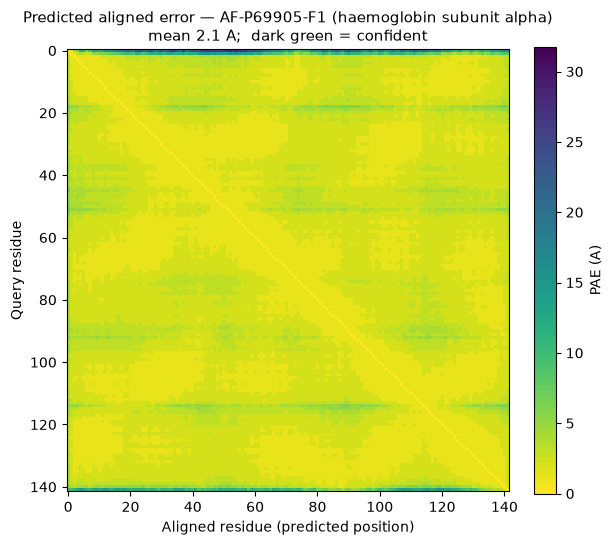

In [33]:
# `viridis_r` puts the confident (low PAE) end dark green at the bottom, and the
# scale is pinned to the API's own reported maximum rather than a guessed constant.
ceiling = record.get("max_predicted_aligned_error") or matrix.max()
fig, ax = plt.subplots(figsize=(6.2, 5.6))
image = ax.imshow(matrix, cmap="viridis_r", origin="upper", vmin=0, vmax=ceiling)
ax.set_xlabel("Aligned residue (predicted position)")
ax.set_ylabel("Query residue")
ax.set_title(
    f"Predicted aligned error — {af_id} (haemoglobin subunit alpha)\n"
    f"mean {matrix.mean():.1f} A;  dark green = confident",
    fontsize=11,
)
fig.colorbar(image, ax=ax, label="PAE (A)", fraction=0.046)
fig.tight_layout()
plt.show()

A uniformly dark matrix: the chain folds as a single rigid unit with low relative
uncertainty. Bright off-diagonal blocks between distant residue pairs are the signature of a
flexible linker or of a multi-domain protein whose domains are only *relatively* uncertain —
neither applies here.

---
## 10. Exporting

### PNG snapshot

`download_image` triggers a browser download; it does not return image bytes, so it does
nothing useful in a headless run. Call it from a live notebook session.

In [34]:
# view.download_image("hemoglobin.png", factor=2, antialias=True)
# `factor` multiplies pixel dimensions; `trim` crops transparent margins.
# Commented out because it is a no-op outside a browser session.

### Standalone HTML

`write_html` serialises the widget state, the structure data and the NGL JavaScript bundle
into a single file you can email or host. Note the argument order: **the filename first, then
the views**. It returns `None` — the result is the file on disk, not a string.

The output is offline-capable in the sense that matters most: the *structure data* and the
widget state are embedded, so the file never re-fetches coordinates from RCSB. It is not
fully self-contained, though — the page still requests the Jupyter HTML manager, jQuery UI,
`require.js` and Font Awesome from CDNs at load time.

In [35]:
output = Path("hemoglobin_nglview.html")
nv.write_html(str(output), [site_view])
print(f"wrote {output}  ({output.stat().st_size / 1024:.0f} KiB)")

wrote hemoglobin_nglview.html  (5958 KiB)


In [36]:
# What is embedded, and what is still fetched at view time?
text = output.read_text(encoding="utf-8")
remote = sorted(set(re.findall(r'https?://[^"\'\s<>()]+', text)))

# Not every URL in the file is a fetch. These hosts are the widget/UI libraries
# the page actually requests; the rest are strings that happen to sit inside the
# embedded metadata.
FETCHED_HOSTS = ("cdn.jsdelivr.net", "cdnjs.cloudflare.com", "use.fontawesome.com")
fetched = [u for u in remote if any(h in u for h in FETCHED_HOSTS)]
inert = [u for u in remote if u not in fetched]

print(f"{len(fetched)} URL(s) the page fetches at load time:")
for url in fetched:
    print("  ", url)
print(f"\n{len(inert)} further URL(s) present as inert text inside the embedded data:")
for url in inert:
    print("  ", url)

print(f"\ncontains inline structure blob: {len(text) > 100_000}")
print("first bytes:", text[:60].replace("\n", " "))

4 URL(s) the page fetches at load time:
   https://cdn.jsdelivr.net/npm/@jupyter-widgets/html-manager@^1.0.1/dist/embed-amd.js
   https://cdnjs.cloudflare.com/ajax/libs/jqueryui/1.12.0/jquery-ui.css
   https://cdnjs.cloudflare.com/ajax/libs/require.js/2.3.4/require.min.js
   https://use.fontawesome.com/releases/v5.15.4/css/all.css

3 further URL(s) present as inert text inside the embedded data:
   http://mmcif.pdb.org/dictionaries/ascii/mmcif_pdbx.dic
   https://creativecommons.org/licenses/by/4.0/
   https://raw.githubusercontent.com/ihmwg/ModelCIF/master/dist/mmcif_ma.dic\n_audit_conform.dict_name

contains inline structure blob: True
first bytes: <!DOCTYPE html> <html lang="en"> <head>     <meta charset="U


Worth knowing before you rely on it: a naive grep for `https://` in the output overstates the
dependencies, because the embedded mmCIF carries dictionary and licence URLs as inert text —
including one with a literal `\n` in the middle of it, which is a JSON escape rather than a
line break. The cell above splits the two kinds apart, and the four it labels as fetched are
the real ones. If you need a truly self-contained artefact with no network at all, screenshot
the view in a browser instead.

---
## 11. Patterns worth memorising

```python
# Fastest possible look at a PDB entry
view = nglview.show_pdbid("1HHO")

# Two structures in one widget, coloured by chain name
view = nglview.show_structure_file("oxy.cif")
view.add_component("deoxy.cif", ext="cif")

# Cartoon + surface + ligand in three lines
view.add_representation("cartoon", "protein", color_scheme="sstruc")
view.add_representation("surface", "protein", opacity=0.4, use_worker=True)
view.add_representation("ball+stick", "hetero and not water", color_scheme="element")

# Dim the background cartoon, recolour the foreground
view.update_representation(0, repr_index=0, opacity=0.15)
view.color_by("chainname", 0)

# Remove a component (UUID or view[0], never an integer index)
view.remove_component(view[0])

# Publish it (filename first, views second)
nglview.write_html("out.html", [view])
```

| Task | Reach for |
| --- | --- |
| Quick look at a PDB entry | `show_pdbid` |
| Load a file you already have | `show_structure_file(path)` |
| Preview a selection | NGL's click picker, or a `Bio.PDB` predicate |
| Distances, contacts, buried surface | `NeighborSearch`, `Bio.PDB.Selection.unfold_neighbors` |
| Secondary structure | `mkdssp` + `Bio.PDB.SSSP`, or the author HELIX/SHEET records |
| Custom colouring by selection | `ColormakerRegistry.add_selection_scheme` |
| Custom colouring by value | `ColormakerRegistry.add_scheme_func` (JavaScript) |
| Model confidence | `color_scheme="bfactor"` on an AlphaFold mmCIF |
| Publication image | `write_html`, then screenshot in a browser |

---
## 12. Caveats

* **Coordinates are not everything.** B-factors, occupancies and alternate conformations
  carry information that no picture shows.
* **Two depositions are not one experiment.** `1HHO` and `2HHB` differ in resolution,
  assembly, crystal form and depositor. Comparing their B-factors or water networks directly
  is not sound.
* **Stereochemistry and valence errors exist in deposited coordinates.** NGL will happily
  draw a malformed bond; validate before drawing conclusions.
* **A crystal is a snapshot.** `1HHO` and `2HHB` bracket the oxygenation extremes, not the
  transition between them.
* **Surfaces are the slow part of the viewer.** On a large complex keep `use_worker=True`,
  lower opacity, or narrow the selection before blaming the GPU.
* **Notebook output is not a test.** This notebook was executed cell by cell to confirm every
  call is valid; the 3D rendering itself is produced in the browser and needs a human to look
  at it.